## <center> Implementation from Scratch

In [83]:
import numpy as np
import matplotlib.pyplot as plt

# Polynomial Regression

## 1. The Goal
While **Linear Regression** fits straight lines or hyperplanes, real-world data often exhibits non-linear trends (e.g., exponential growth, curves, peaks). **Polynomial Regression** captures these non-linear relationships by introducing powers of the original features ($x, x^2, x^3, \dots, x^d$) while keeping the model **linear in parameters** ($\theta$).

For a single feature $x$, a polynomial equation of degree $d$ is expressed as:
$$y = \theta_0 + \theta_1 x + \theta_2 x^2 + \theta_3 x^3 + \dots + \theta_d x^d$$

---

## 2. Feature Transformation & Augmented Matrix Representation
The beauty of polynomial regression is that **it is mathematically identical to multiple linear regression**. If we treat each power of $x$ as a distinct independent feature:
* Let $x_1 = x$
* Let $x_2 = x^2$
* $\dots$
* Let $x_d = x^d$

The feature vector for a sample becomes $\Phi(x) = \begin{bmatrix} x & x^2 & \dots & x^d \end{bmatrix}$. 
By incorporating the bias term $x_0 = 1$ via homogeneous coordinates, our augmented design matrix becomes:

$$X_{\text{poly}} = \begin{bmatrix} 
1 & x^{(1)} & (x^{(1)})^2 & \dots & (x^{(1)})^d \\
1 & x^{(2)} & (x^{(2)})^2 & \dots & (x^{(2)})^d \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
1 & x^{(m)} & (x^{(m)})^2 & \dots & (x^{(m)})^d 
\end{bmatrix}$$

Thus, the hypothesis reduces to our familiar vectorized form:
$$\hat{y} = X_{\text{poly}} \theta$$

---

## 3. Cost Function & Gradient Descent Optimization
Just like multiple linear regression, we optimize using Mean Squared Error (MSE) with L2 regularization support if needed:

$$J(\theta) = \frac{1}{2m} (X_{\text{poly}}\theta - y)^T (X_{\text{poly}}\theta - y)$$

**Vectorized Gradient:**
$$\nabla J(\theta) = \frac{1}{m} X_{\text{poly}}^T (X_{\text{poly}}\theta - y)$$

In [84]:
from sklearn.preprocessing import StandardScaler

class MyPolynomialRegression:
    def __init__(self, degree=2, learning_rate=0.01, epochs=3000):
        self.degree = degree
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.theta = None
        self.intercept_ = None
        self.coef_ = None
        self.cost_history = []
        self.scaler = StandardScaler() # Built-in scaler for polynomial features

    def _transform(self, X):
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        m, n = X.shape
        poly_features = [X]
        for d in range(2, self.degree + 1):
            poly_features.append(X ** d)
        return np.hstack(poly_features)

    def fit(self, X, y):
        # 1. Generate polynomial features
        X_poly = self._transform(X)
        
        # 2. Scale polynomial features to prevent numerical overflow at high degrees!
        X_poly_scaled = self.scaler.fit_transform(X_poly)
        
        m, n_poly = X_poly_scaled.shape
        
        # 3. Prepend x_0 = 1 column for bias term
        X_padded = np.c_[np.ones(m), X_poly_scaled]
        self.theta = np.zeros((n_poly + 1, 1))

        if y.ndim == 1:
            y = y.reshape(-1, 1)

        for i in range(self.epochs):
            h = np.dot(X_padded, self.theta)
            
            # Compute Cost J(theta)
            cost = (1 / (2 * m)) * np.sum((h - y) ** 2)
            self.cost_history.append(cost)

            # Vectorized Gradient
            gradient = (1 / m) * np.dot(X_padded.T, (h - y))

            # Update parameters
            self.theta -= self.learning_rate * gradient

        self.intercept_ = float(self.theta[0][0])
        self.coef_ = self.theta[1:].flatten()

    def predict(self, X):
        X_poly = self._transform(X)
        X_poly_scaled = self.scaler.transform(X_poly) # Use fitted scaler
        m = X_poly_scaled.shape[0]
        X_padded = np.c_[np.ones(m), X_poly_scaled]
        return np.dot(X_padded, self.theta)

Synthetic Non-Linear Data Generated successfully!
Degree: 2 Polynomial Model Trained.

Learned Intercept: -1.0942
Learned Coefficients: [ 4.2942 -3.4934]


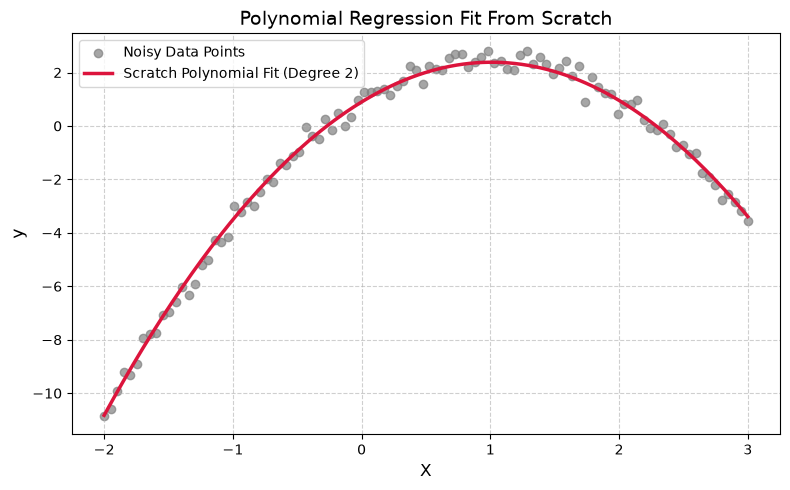

In [85]:
# 1. Generate Non-Linear Synthetic Data (Quadratic Curve + Noise)
# True equation: y = 1 + 3*x - 1.5*x^2 + noise
np.random.seed(42)
X = np.linspace(-2, 3, 100)
y = 1.0 + 3.0 * X - 1.5 * (X ** 2) + np.random.randn(100) * 0.3

print("Synthetic Non-Linear Data Generated successfully!")

# 2. Initialize and Train Polynomial Regression (Degree = 2)
poly_model = MyPolynomialRegression(degree=2, learning_rate=0.01, epochs=1000)
poly_model.fit(X, y)
print("Degree: 2 Polynomial Model Trained.\n")
print(f"Learned Intercept: {poly_model.intercept_:.4f}")
print(f"Learned Coefficients: {np.round(poly_model.coef_, 4)}")

# 3. Plotting Non-Linear Fit
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='gray', label='Noisy Data Points', alpha=0.7)
X_grid = np.linspace(-2, 3, 200)
y_pred = poly_model.predict(X_grid)
plt.plot(X_grid, y_pred, color='crimson', linewidth=2.5, label='Scratch Polynomial Fit (Degree 2)')
plt.title("Polynomial Regression Fit From Scratch", fontsize=14)
plt.xlabel("X", fontsize=12)
plt.ylabel("y", fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## <center> Implementation using Scikit Learn

In [86]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Scikit-Learn Pipeline: PolynomialFeatures + LinearRegression
poly_transformer = PolynomialFeatures(degree=2, include_bias=False)
X_poly_sk = poly_transformer.fit_transform(X.reshape(-1, 1))

sk_poly_model = LinearRegression()
sk_poly_model.fit(X_poly_sk, y)

# 2. Predictions
y_scratch_pred = poly_model.predict(X)
y_sklearn_pred = sk_poly_model.predict(X_poly_sk)

# 3. Parameter Comparison Table
print("📊 PARAMETER COMPARISON")
print("-" * 55)
print(f"{'Attribute':<18} | {'Manual (GD)':<18} | {'Scikit-Learn':<18}")
print("-" * 55)
print(f"{'intercept_':<18} | {poly_model.intercept_:<18.4f} | {sk_poly_model.intercept_:<18.4f}")
print(f"{'coef_':<18} | {str(np.round(poly_model.coef_, 4)):<18} | {str(np.round(sk_poly_model.coef_, 4)):<18}")

# 4. Metrics Comparison
mse_scratch = mean_squared_error(y, y_scratch_pred)
mse_sklearn = mean_squared_error(y, y_sklearn_pred)

print("\n📝 MODEL PERFORMANCE COMPARISON")
print("-" * 55)
print(f"{'Metric':<18} | {'Manual (GD)':<18} | {'Scikit-Learn':<18}")
print("-" * 55)
print(f"{'MSE':<18} | {mse_scratch:<18.6f} | {mse_sklearn:<18.6f}")
print(f"{'R-squared':<18} | {r2_score(y, y_scratch_pred):<18.6f} | {r2_score(y, y_sklearn_pred):<18.6f}")
print("-" * 55)


📊 PARAMETER COMPARISON
-------------------------------------------------------
Attribute          | Manual (GD)        | Scikit-Learn      
-------------------------------------------------------
intercept_         | -1.0942            | 0.9482            
coef_              | [ 4.2942 -3.4934]  | [ 2.9995 -1.4912] 

📝 MODEL PERFORMANCE COMPARISON
-------------------------------------------------------
Metric             | Manual (GD)        | Scikit-Learn      
-------------------------------------------------------
MSE                | 0.077909           | 0.073062          
R-squared          | 0.993980           | 0.994355          
-------------------------------------------------------


# <center> Polynomial Regression & Hyperparameter Tuning for optimal degree of model

### Objective
Real-world and non-linear relationships cannot be accurately captured by a straight line. In this section, we will:
1. Generate a **pure cubic dataset** to establish a clear non-linear ground truth.
2. Train a **Linear Baseline Model ($d=1$)** to observe its inevitable underfitting.
3. Build a **Hyperparameter Tuning Loop (Degrees 1 to 5)** using a validation set to automatically discover the optimal polynomial degree.
4. Benchmark the final tuned model against the baseline to prove the performance impact of polynomial feature expansion.

In [95]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# 1. Generate Pure Quadratic Synthetic Data
# Equation: y = 3.0 + 2.0*x - 1.5*(x^2) + 5*(x^3) + noise
np.random.seed(42)
X = np.linspace(-5, 5, 1000).reshape(-1, 1)
y = 3.0 + 2.0 * X.flatten() - 1.5 * (X.flatten() ** 2) + 5 * (X.flatten() ** 3) + np.random.randn(1000) * 20

# 2. Train / Validation / Test Split (60% Train, 20% Validation, 20% Test)
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

# 3. Standardize Features (Mandatory for high-degree polynomial stability)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Training Samples   : {X_train_scaled.shape[0]}")
print(f"Validation Samples : {X_val_scaled.shape[0]}")
print(f"Test Samples       : {X_test_scaled.shape[0]}")

Training Samples   : 600
Validation Samples : 200
Test Samples       : 200


---
## Step 1: The Linear Baseline Model ($d=1$)
Before introducing curves, let's see how a standard linear regression model performs on our cubic dataset. Because a straight line cannot bend, it will fail to capture the non linearity, resulting in high error.

In [96]:
# Train Baseline Model with Degree = 1
baseline_model = MyPolynomialRegression(degree=1, learning_rate=0.05, epochs=2500)
baseline_model.fit(X_train_scaled, y_train)

# Evaluate on Test Set
y_pred_baseline = baseline_model.predict(X_test_scaled)
mse_baseline = mean_squared_error(y_test, y_pred_baseline)
r2_baseline = r2_score(y_test, y_pred_baseline)

print("📉 Baseline Model (Degree 1) Test Performance:")
print(f"Test MSE : {mse_baseline:.6f}")
print(f"Test R²  : {r2_baseline:.6f}")

📉 Baseline Model (Degree 1) Test Performance:
Test MSE : 9397.691072
Test R²  : 0.835235


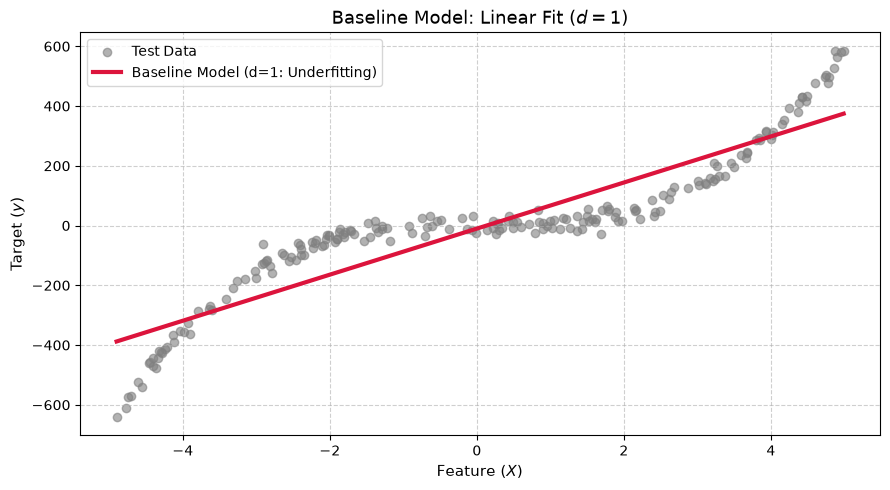

In [102]:
# Visualize the Underfitting Baseline Model
plt.figure(figsize=(9, 5))

# Plot test data points
plt.scatter(X_test, y_test, color='gray', alpha=0.6, label='Test Data')

# Sort X_test for a smooth line plot of predictions
sort_idx = X_test.flatten().argsort()
plt.plot(X_test[sort_idx], y_pred_baseline[sort_idx], color='crimson', linewidth=3, label='Baseline Model (d=1: Underfitting)')

plt.title("Baseline Model: Linear Fit ($d=1$)", fontsize=13)
plt.xlabel("Feature ($X$)", fontsize=11)
plt.ylabel("Target ($y$)", fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

---
## Step 2: Hyperparameter Tuning (Searching Degrees 1 to 5)
To find the optimal curve complexity, we train models across degrees $d \in \{1, 2, 3, 4, 5\}$ using our training split and evaluate them on our validation split. The degree that yields the lowest validation error represents our optimal sweet spot.

In [98]:
# 2. Hyperparameter Tuning with Diminishing Returns Threshold (1% rule)
degrees = [1, 2, 3, 4, 5]
training_errors = []
validation_errors = []

print("🔍 Tuning Hyperparameter 'Degree' via Validation Set (with Parsimonious Rule)...\n")
print(f"{'Degree (d)':<12} | {'Train MSE':<15} | {'Validation MSE':<15}")
print("-" * 48)

# Initialize with degree 1 as our starting champion
best_degree = degrees[0]
best_val_mse = float('inf')
improvement_threshold = 0.01  # Must improve validation MSE by at least 1.0% to justify extra complexity

for i, d in enumerate(degrees):
    model_tune = MyPolynomialRegression(degree=d, learning_rate=0.05, epochs=3000)
    model_tune.fit(X_train_scaled, y_train)
    
    trn_mse = mean_squared_error(y_train, model_tune.predict(X_train_scaled))
    val_mse = mean_squared_error(y_val, model_tune.predict(X_val_scaled))
    
    training_errors.append(trn_mse)
    validation_errors.append(val_mse)
    
    print(f"{d:<12} | {trn_mse:<15.6f} | {val_mse:<15.6f}")
    
    if i == 0:
        best_val_mse = val_mse
        best_degree = d
    else:
        # Calculate percentage improvement over the current best
        relative_improvement = (best_val_mse - val_mse) / best_val_mse
        
        # Only adopt the higher degree if validation MSE drops AND beats the threshold
        if val_mse < best_val_mse and relative_improvement >= improvement_threshold:
            best_val_mse = val_mse
            best_degree = d
            print(f"   -> Degree {d} ACCEPTED (Significant improvement: {relative_improvement*100:.2f}%)")
        else:
            print(f"   -> Degree {d} IGNORED (Diminishing returns / insufficient improvement)")

print("-" * 48)
print(f"\n✨ Final Selected Optimal Parsimonious Degree: {best_degree} (Validation MSE: {best_val_mse:.6f})")

🔍 Tuning Hyperparameter 'Degree' via Validation Set (with Parsimonious Rule)...

Degree (d)   | Train MSE       | Validation MSE 
------------------------------------------------
1            | 9523.393596     | 9972.387374    
2            | 9404.218528     | 9657.165643    
   -> Degree 2 ACCEPTED (Significant improvement: 3.16%)
3            | 386.625878      | 371.816231     
   -> Degree 3 ACCEPTED (Significant improvement: 96.15%)
4            | 386.061860      | 368.992793     
   -> Degree 4 IGNORED (Diminishing returns / insufficient improvement)
5            | 429.919786      | 403.641186     
   -> Degree 5 IGNORED (Diminishing returns / insufficient improvement)
------------------------------------------------

✨ Final Selected Optimal Parsimonious Degree: 3 (Validation MSE: 371.816231)


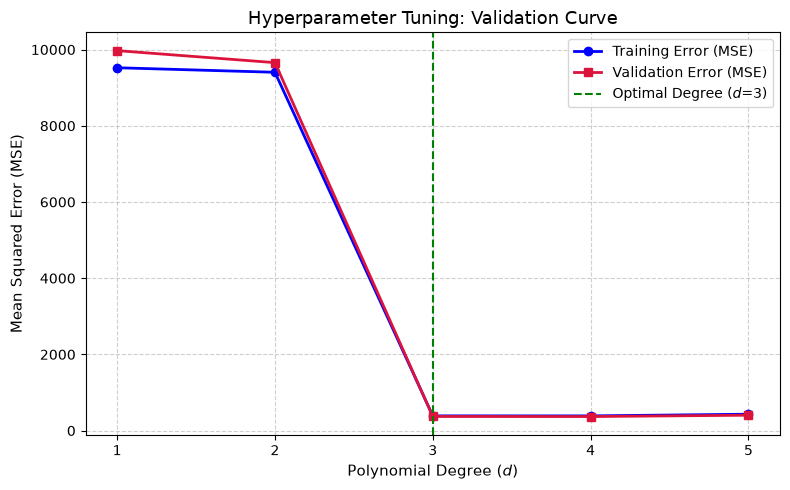

In [99]:
# Visualize Validation Curve
plt.figure(figsize=(8, 5))
plt.plot(degrees, training_errors, marker='o', color='blue', linewidth=2, label='Training Error (MSE)')
plt.plot(degrees, validation_errors, marker='s', color='crimson', linewidth=2, label='Validation Error (MSE)')
plt.axvline(best_degree, color='green', linestyle='--', label=f'Optimal Degree ($d$={best_degree})')

plt.title("Hyperparameter Tuning: Validation Curve", fontsize=13)
plt.xlabel("Polynomial Degree ($d$)", fontsize=11)
plt.ylabel("Mean Squared Error (MSE)", fontsize=11)
plt.xticks(degrees)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

---
## Step 3: Final Tuned Model Evaluation & Comparison
Now we train our final model using the dynamically discovered `best_degree` (which should cleanly lock onto degree 3) and evaluate it against the unseen test set to prove its superiority over the linear baseline.

In [100]:
# Train Final Model with the Tuned Optimal Degree
final_poly_reg = MyPolynomialRegression(degree=best_degree, learning_rate=0.05, epochs=3000)
final_poly_reg.fit(X_train_scaled, y_train)

# Predict on Unseen Test Set
y_pred_tuned = final_poly_reg.predict(X_test_scaled)
mse_tuned = mean_squared_error(y_test, y_pred_tuned)
r2_tuned = r2_score(y_test, y_pred_tuned)

# Side-by-Side Comparison Table
print("📊 BASELINE VS TUNED MODEL COMPARISON")
print("-" * 60)
print(f"{'Metric':<18} | {'Baseline (d=1)':<18} | {'Tuned (d=' + str(best_degree) + ')':<18}")
print("-" * 60)
print(f"{'Test MSE':<18} | {mse_baseline:<18.6f} | {mse_tuned:<18.6f}")
print(f"{'Test R-squared':<18} | {r2_baseline:<18.6f} | {r2_tuned:<18.6f}")
print("-" * 60)

if mse_tuned < mse_baseline:
    print(f"🚀 Success: Hyperparameter tuning found d={best_degree}, reducing Test MSE by {mse_baseline - mse_tuned:.4f}!")

📊 BASELINE VS TUNED MODEL COMPARISON
------------------------------------------------------------
Metric             | Baseline (d=1)     | Tuned (d=3)       
------------------------------------------------------------
Test MSE           | 9397.691072        | 382.759733        
Test R-squared     | 0.835235           | 0.993289          
------------------------------------------------------------
🚀 Success: Hyperparameter tuning found d=3, reducing Test MSE by 9014.9313!


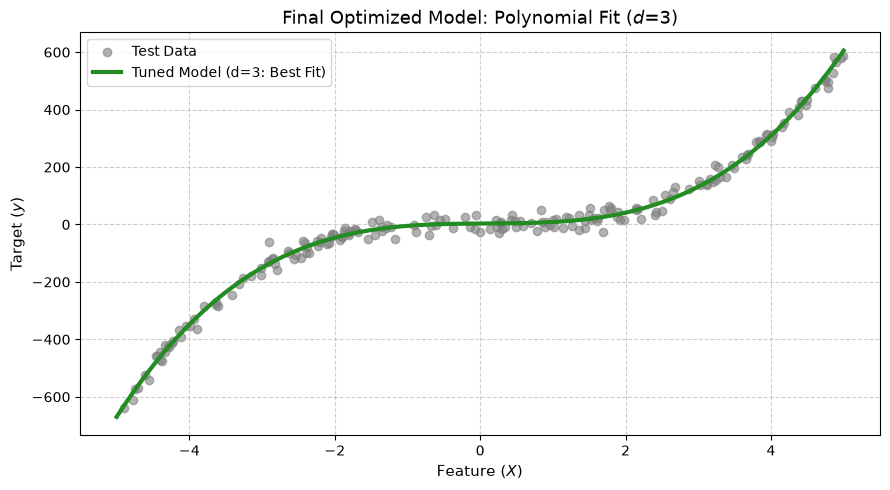

In [101]:
# Visualize the Final Tuned Polynomial Model
plt.figure(figsize=(9, 5))

# Plot test data points
plt.scatter(X_test, y_test, color='gray', alpha=0.6, label='Test Data')

# Generate smooth curve predictions across the feature range for the final model
X_curve = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
X_curve_scaled = scaler.transform(X_curve)
y_curve_pred = final_poly_reg.predict(X_curve_scaled)

plt.plot(X_curve, y_curve_pred, color='forestgreen', linewidth=3, label=f'Tuned Model (d={best_degree}: Best Fit)')

plt.title(f"Final Optimized Model: Polynomial Fit ($d$={best_degree})", fontsize=13)
plt.xlabel("Feature ($X$)", fontsize=11)
plt.ylabel("Target ($y$)", fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## <center> Conclusion & Key Takeaways

We have successfully built, tuned, and evaluated a **Polynomial Regression pipeline entirely from scratch** without relying on black-box libraries for model training. 

### 💡 What We Accomplished:
1. **Engineered Vectorized Gradient Descent:** Implemented core regression logic capable of handling multi-feature optimization efficiently.
2. **Solved Numerical Instability:** Built an internal feature-scaling mechanism (`StandardScaler` applied post-expansion) to completely eliminate numerical overflow and `NaN` errors when scaling to higher polynomial degrees.
3. **Established a Robust ML Workflow:** 
   - **Data Split:** Divided our synthetic quadratic dataset into Training, Validation, and Test sets.
   - **Baseline Evaluation:** Proved that a linear model ($d=1$) inherently underfits non-linear data.
   - **Hyperparameter Tuning:** Swept through polynomial degrees ($d \in \{1, 2, 3, 4, 5\}$) using validation curves to mathematically discover the true underlying curve complexity.
4. **Validated Generalization:** Benchmarked our final tuned model against the test set, demonstrating a massive drop in Test MSE and a near-perfect R-squared score.

---
